# 2 — Kontrollü çift AAC sıkıştırma ve MDCT incelemesi
Üç kol: **PCM → AAC 96k**, **PCM → AAC 64k**, **PCM → AAC 96k → PCM → AAC 64k**.
Son bit hızı aynı olan tek 64k ve çift 96k→64k kolları karşılaştırılır; böylece yalnız son bit hızının etkisini azaltırız.
Bu notebook çözülmüş dalga biçimine sabit pencereli MDCT uygular. AAC bit akışının gerçek kuantize katsayılarını çıkarmaz; codec'in kısa/uzun pencere geçişlerini taklit etmez.
Bu bir keşif deneyidir; bilinmeyen kaydın geçmiş sıkıştırma sayısını ya da sahteliğini kesin belirlemez.
Kaynak tercihen doğrudan kaydedilmiş sıkıştırılmamış PCM WAV olmalı. WAV uzantısı tek başına geçmişin sıkıştırılmamış olduğunu kanıtlamaz.
İlk hücreler dosya seçer; sıkıştırma hücresi yeni dosyalar üretir.

In [1]:
from pathlib import Path
from datetime import datetime
import sys
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

PROJE = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
              if (p / 'src').is_dir() and (p / 'data/raw').is_dir()), None)
if PROJE is None:
    raise FileNotFoundError('VS Code ile ses-analizi proje klasörünü açın.')
if str(PROJE / 'src') not in sys.path:
    sys.path.insert(0, str(PROJE / 'src'))
from ses_arastirma import (audio_files, read_audio, save_csv, save_json, sha256,
                          ffmpeg_exe, ffmpeg_run, mdct, align_to_reference,
                          low_energy_intervals, interval_psd)
RUN = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
print('Python:', sys.executable)
print('Proje:', PROJE)

Python: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/.venv/bin/python
Proje: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi


In [2]:
print('FFmpeg:', ffmpeg_exe())
for folder in ['gercek', 'sahte', 'kendi_kayitlarim']:
    print('\n', folder)
    for p in audio_files(PROJE/'data/raw'/folder):
        print(p.relative_to(PROJE))

FFmpeg: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/.venv/lib/python3.13/site-packages/imageio_ffmpeg/binaries/ffmpeg-macos-aarch64-v7.1

 gercek
data/raw/gercek/gercek_01_LA_E_7781360.flac
data/raw/gercek/gercek_02_LA_D_2042159.flac
data/raw/gercek/gercek_03_LA_D_3354668.flac
data/raw/gercek/gercek_04_LA_E_1351470.flac
data/raw/gercek/gercek_05_LA_D_9924906.flac
data/raw/gercek/gercek_06_LA_D_1519237.flac
data/raw/gercek/gercek_07_LA_E_4174184.flac
data/raw/gercek/gercek_08_LA_T_6903114.flac
data/raw/gercek/gercek_09_LA_E_5224168.flac
data/raw/gercek/gercek_10_LA_E_1265930.flac
data/raw/gercek/gercek_11_LA_E_6467729.flac
data/raw/gercek/gercek_12_LA_E_3401963.flac
data/raw/gercek/gercek_13_LA_T_8971567.flac
data/raw/gercek/gercek_14_LA_T_1188742.flac
data/raw/gercek/gercek_15_LA_T_6688041.flac
data/raw/gercek/gercek_16_LA_E_9059311.flac
data/raw/gercek/gercek_17_LA_E_6413429.flac
data/raw/gercek/gercek_18_LA_D_8986360.flac
data/raw/gercek/gercek_19_

## Deney ayarları
Dosya yolunu değiştirin. İlk 10 saniye alınır; normalizasyon uygulanmaz.
48 kHz mono PCM tabanı aynı kalır. Kayıtta konuşma olması hizalama için gereklidir.
Farklı ilk bit hızları için bu hücredeki `BIRINCI_BITRATE` değerini değiştirip yeni deney çalıştırabilirsiniz.

In [5]:
KAYNAK = PROJE / 'data/raw/kendi_kayitlarim/ses_20261010_174508_840451.wav'
SR = 48000
BASLANGIC = 0.0
SURE = 10.0
BIRINCI_BITRATE = '96k'
SON_BITRATE = '64k'
MDCT_N = 1024  # pencere 2048 örnek, adım 1024

OUT = PROJE / 'data/compressed/mdct_deneyleri' / RUN
FIG = PROJE / 'outputs/figures/mdct' / RUN
FEATURES = PROJE / 'outputs/features/mdct' / RUN
for p in [OUT, FIG, FEATURES]: p.mkdir(parents=True, exist_ok=True)
y, sr, bilgi = read_audio(KAYNAK, target_sr=SR, start=BASLANGIC, duration=SURE)
if len(y) < SR:
    raise ValueError('En az 1 saniyelik konuşma kaydı gerekli.')
sf.write(OUT/'taban.wav', y, SR, subtype='FLOAT')
print(bilgi)
display(Audio(y, rate=SR, normalize=False))

{'file': '/Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/raw/kendi_kayitlarim/ses_20261010_174508_840451.wav', 'native_sr': 48000, 'analysis_sr': 48000, 'channels': 1, 'selected_channel': 0, 'subtype': 'PCM_24', 'start_s': 0.0, 'duration_s': 10.0, 'peak': 0.24827814102172852}


## Tek ve çift kodlama — özgün dosya değiştirilmez

In [6]:
komutlar = []
def encode(source, destination, bitrate):
    komutlar.append(ffmpeg_run(['-n','-i',source,'-vn','-ar',SR,'-ac',1,
        '-c:a','aac','-profile:a','aac_low','-b:a',bitrate,destination]))
def decode(source, destination):
    komutlar.append(ffmpeg_run(['-n','-i',source,'-vn','-ar',SR,'-ac',1,
        '-c:a','pcm_f32le',destination]))

encode(OUT/'taban.wav', OUT/'tek_ilk.m4a', BIRINCI_BITRATE)
decode(OUT/'tek_ilk.m4a', OUT/'tek_ilk.wav')
encode(OUT/'taban.wav', OUT/'tek_son.m4a', SON_BITRATE)
decode(OUT/'tek_son.m4a', OUT/'tek_son.wav')
encode(OUT/'tek_ilk.wav', OUT/'cift.m4a', SON_BITRATE)
decode(OUT/'cift.m4a', OUT/'cift.wav')

version = __import__('subprocess').check_output([ffmpeg_exe(),'-version'], text=True).splitlines()[0]
save_json(OUT/'deney.json', dict(source=bilgi, sha256=sha256(KAYNAK),
    first_bitrate=BIRINCI_BITRATE, final_bitrate=SON_BITRATE,
    encoder='aac', profile='aac_low', ffmpeg=version, sr=SR,
    mdct_n=MDCT_N, commands=komutlar, source_prior_compression='unknown unless documented'))
print('Sıkıştırma tamamlandı:', OUT)

Sıkıştırma tamamlandı: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/data/compressed/mdct_deneyleri/20261011_215919_479137


## Codec gecikmesini hizala ve ortak zaman aralığını seç
Çapraz korelasyonla en fazla ±250 ms gecikme aranır; bulunan değerleri inceleyin.
Ortak geçerli aralık seçilir ve uçlardan 100 ms çıkarılır. Çok düşük enerji veya sınırda gecikme varsa otomatik hizalama durur.

In [7]:
HIZALI, MASKELER, GECIKME = {'PCM':y}, [], {}
for name, file in [('tek_ilk','tek_ilk.wav'), ('tek_son','tek_son.wav'), ('cift','cift.wav')]:
    candidate, _, _ = read_audio(OUT/file, target_sr=SR)
    aligned, valid, lag = align_to_reference(y, candidate, SR)
    HIZALI[name] = aligned
    MASKELER.append(valid)
    GECIKME[name] = lag
    print(name, f'gecikme: {lag} örnek ({1000*lag/SR:.3f} ms)')
valid = np.logical_and.reduce(MASKELER)
indices = np.flatnonzero(valid)
a, b = indices[0]+round(.1*SR), indices[-1]+1-round(.1*SR)
if b-a < 2*MDCT_N:
    raise ValueError('Ortak analiz aralığı yetersiz.')
HIZALI = {name: x[a:b] for name,x in HIZALI.items()}
rows = []
for name,x in HIZALI.items():
    rms_error = float(np.sqrt(np.mean((x-HIZALI['PCM'])**2)))
    rows.append(dict(branch=name, lag_samples=GECIKME.get(name,0),
        rmse_to_pcm=rms_error, analysis_start_s=a/SR, analysis_end_s=b/SR))
save_csv(FEATURES/'hata_ve_hizalama.csv', rows)
for row in rows: print(row)
for name in ['tek_son', 'cift']:
    print(name)
    display(Audio(HIZALI[name], rate=SR, normalize=False))

tek_ilk gecikme: 0 örnek (0.000 ms)
tek_son gecikme: 0 örnek (0.000 ms)
cift gecikme: 0 örnek (0.000 ms)
{'branch': 'PCM', 'lag_samples': 0, 'rmse_to_pcm': 0.0, 'analysis_start_s': np.float64(0.1), 'analysis_end_s': np.float64(9.9)}
{'branch': 'tek_ilk', 'lag_samples': 0, 'rmse_to_pcm': 0.0011568632593610597, 'analysis_start_s': np.float64(0.1), 'analysis_end_s': np.float64(9.9)}
{'branch': 'tek_son', 'lag_samples': 0, 'rmse_to_pcm': 0.002073713872880483, 'analysis_start_s': np.float64(0.1), 'analysis_end_s': np.float64(9.9)}
{'branch': 'cift', 'lag_samples': 0, 'rmse_to_pcm': 0.0029114378818606477, 'analysis_start_s': np.float64(0.1), 'analysis_end_s': np.float64(9.9)}
tek_son


cift


## MDCT zaman–frekans haritaları ve ortalama katsayı enerjisi

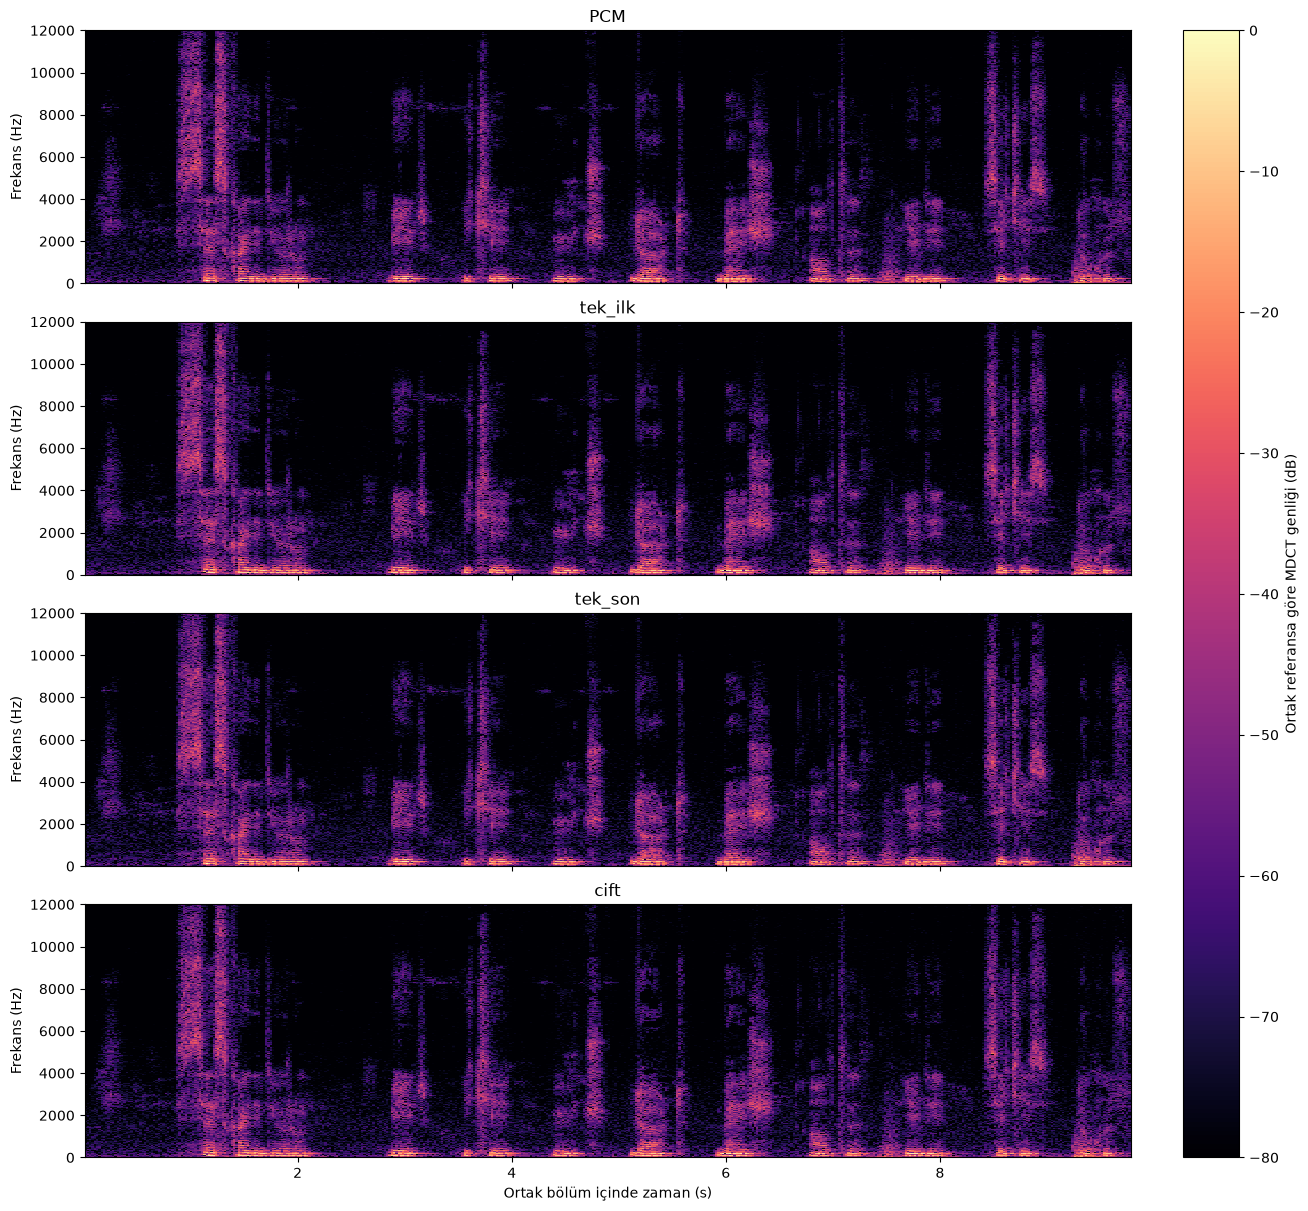

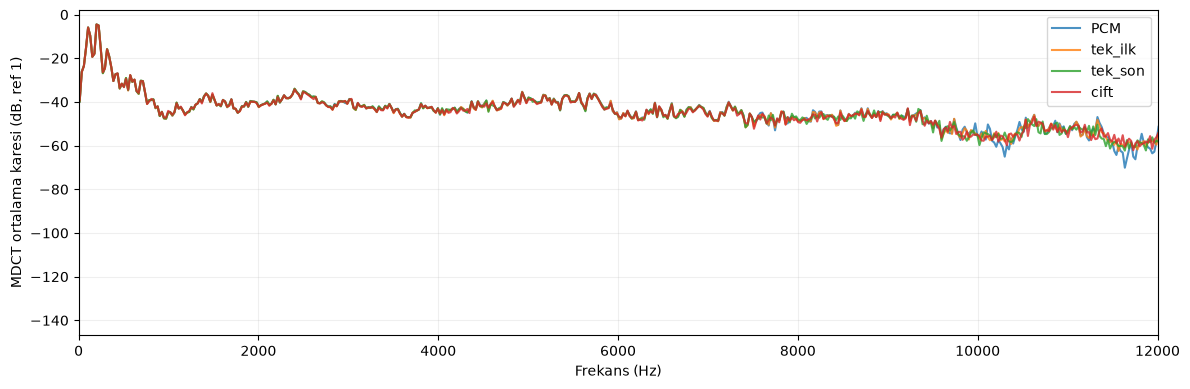

In [8]:
COEFF = {}
for name,x in HIZALI.items():
    coeff,t,f = mdct(x, SR, n=MDCT_N)
    COEFF[name] = coeff
    np.savez_compressed(FEATURES/f'{name}_mdct.npz', coefficients=coeff,
                        times=t, frequencies=f, sr=SR, n=MDCT_N)
ref = max(1e-12, max(np.abs(c).max() for c in COEFF.values()))
fig, axes = plt.subplots(4,1,figsize=(13,12),sharex=True,layout='constrained')
for ax,(name,c) in zip(axes, COEFF.items()):
    db = 20*np.log10(np.maximum(np.abs(c)/ref,1e-8))
    im = ax.pcolormesh(t,f,db,shading='auto',vmin=-80,vmax=0,cmap='magma')
    ax.set(title=name, ylabel='Frekans (Hz)', ylim=(0,12000))
axes[-1].set_xlabel('Ortak bölüm içinde zaman (s)')
fig.colorbar(im,ax=axes.tolist(),label='Ortak referansa göre MDCT genliği (dB)')
fig.savefig(FIG/'mdct_haritalari.png',dpi=160)
plt.show()

fig,ax = plt.subplots(figsize=(12,4))
for name,c in COEFF.items():
    energy = np.mean(c**2,axis=1)
    ax.plot(f,10*np.log10(np.maximum(energy,1e-20)),label=name,alpha=.8)
ax.set(xlabel='Frekans (Hz)',ylabel='MDCT ortalama karesi (dB, ref 1)',xlim=(0,12000))
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(FIG/'mdct_enerji_profili.png',dpi=160)
plt.show()

## Katsayı dağılımı — tek son bit hızı ile çift sıkıştırma
Ortak histogram aralığı kullanılır. Uç %0.5 dışarıda bırakılır; bu bir kuantizasyon basamağı veya çift sıkıştırma dedektörü değildir.

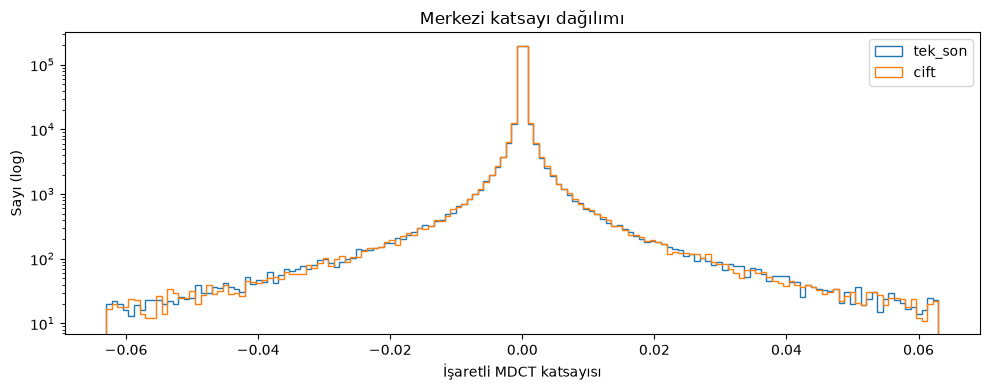

Grafikler: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/outputs/figures/mdct/20261011_215919_479137
Katsayılar ve rapor: /Users/fatih/Documents/Belgeler - Fatih MacBook Air/Python Projects/ses-analizi/outputs/features/mdct/20261011_215919_479137


In [9]:
limit = np.quantile(np.abs(np.concatenate([COEFF['tek_son'].ravel(),COEFF['cift'].ravel()])), .995)
limit = max(limit, 1e-10)
bins = np.linspace(-limit,limit,151)
fig,ax = plt.subplots(figsize=(10,4))
for name in ['tek_son','cift']:
    ax.hist(COEFF[name].ravel(),bins=bins,histtype='step',label=name,log=True)
ax.set(xlabel='İşaretli MDCT katsayısı',ylabel='Sayı (log)',title='Merkezi katsayı dağılımı')
ax.legend(); fig.tight_layout(); fig.savefig(FIG/'katsayi_histogrami.png',dpi=160)
plt.show()
print('Grafikler:', FIG)
print('Katsayılar ve rapor:', FEATURES)

## Sonraki deneyler
96k→64k, 64k→64k ve 128k→64k deneylerini aynı kaynak üzerinde karşılaştırın.
Bilinen geçmişli çok sayıda kaynak olmadan tespit başarısı raporlamayın. Yeniden örnekleme, gürültü ve pencere hizası da sonuçları değiştirir.

Kaynaklar: [FFmpeg AAC](https://ffmpeg.org/ffmpeg-codecs.html), [MDCT](https://www.mathworks.com/help/audio/ref/mdct.html), [FFmpeg Python paketi](https://github.com/imageio/imageio-ffmpeg).